# CS-6600 Project Part 1 - Exploratory Data Analysis

*Weber State University*

**Your Team**: YOUR TEAM NAME AND NAMES OF TEAM MEMBERS HERE : Jeffery Hatch, Fred Walter, Issac Christensen

Your analysis should be below. Unlike previous assignments, there's not a lot of scaffolding provided for you. It's mostly up to you.

## Three questions
1. Can we identify the authoring LLM when evaluating responses to prompts not included in the training.
2.
3.

In [ ]:
# Run this cell and paste your api token in before running other cells, you have to verify your identity too it seems   www.kaggle.com/competitions/name-that-llm/overview/description

import kagglehub
kagglehub.login()

Kaggle credentials set.
Kaggle credentials successfully validated.


In [ ]:

# Packages
%pip install -q kagglehub pandas numpy matplotlib seaborn scikit-learn


# Imports
from pathlib import Path
import kagglehub
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns

# Testing that everything connected properly.
path = kagglehub.competition_download("name-that-llm")
data = pd.read_csv(Path(path) / "train.csv")

print("Number of rows:", len(data))
print("Columns:", data.columns.tolist())
display(data.head())
print("\nFirst paragraph:")
print(data.loc[0, "text"])
print("\nModel that wrote it:")
print(data.loc[0, "model"])

100%|██████████| 854k/854k [00:00<00:00, 81.8MB/s]

Extracting files...
Number of rows: 2699
Columns: ['id', 'prompt_id', 'text', 'model']


,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash



First paragraph:
When a language dies, a particular astronomy dims: not only names for stars, but whole grammars of attention that taught speakers how to read the night. Some tongues map the sky by kinship, binding the Milky Way to ancestors, rivers, or the migration paths of birds; others encode lunar phases as verbs, so time is not a line but a recurring breath. A word can carry the exact color of dawn on snow, the etiquette of speaking to thunder, or the mathematics woven into knot calendars and oral star charts. With extinction, those relations collapse into silence. No dictionary can resurrect the sky those speakers inhabited, nor the quiet ethics it taught. We lose metaphors that made the universe intimate, ethical, and alive, cosmologies in which darkness is a listener, comets are warnings carried by relatives, and constellations are not fixed pictures but seasonal responsibilities. The loss is not merely lexical; it is the erasure of possible human answers to wonder. What rema

In [ ]:
# Looking at how many samples per model and for any missing data or duplicate data
print("Missing values in each column:")
display(data.isna().sum().to_frame("missing_count"))
print("\nNumber of different prompts:")
print(data["prompt_id"].nunique())
print("\nNumber of different LLMs:")
print(data["model"].nunique())
print("\nParagraphs written by each LLM:")
display(data["model"].value_counts().to_frame("paragraph_count"))
print("\nNumber of repeated identical paragraphs:")
print(data["text"].duplicated().sum())

Missing values in each column:


,missing_count
id,0
prompt_id,0
text,0
model,0



Number of different prompts:
150

Number of different LLMs:
18

Paragraphs written by each LLM:


,paragraph_count
model,
qwen3.8-max,150
claude-sonnet-5,150
gemini-3.6-flash,150
gpt-5.6-terra,150
glm-5.3-flash,150
gemini-3.1-pro-preview,150
gemini-3.8-flash,150
claude-opus-4-6,150
gpt-5.6-luna,150



Number of repeated identical paragraphs:
0


,min,median,mean,max
model,,,,
claude-fable-5,39,100.0,112.5,252
claude-opus-4-6,42,98.5,115.1,274
claude-opus-4-8,42,109.0,123.6,251
claude-opus-5,39,116.5,123.4,257
claude-sonnet-5,39,99.5,120.0,267
gemini-3.1-pro-preview,38,104.0,119.3,262
gemini-3.6-flash,40,95.5,111.2,238
gemini-3.7-flash,40,101.5,117.1,252
gemini-3.8-flash,41,84.0,100.7,238


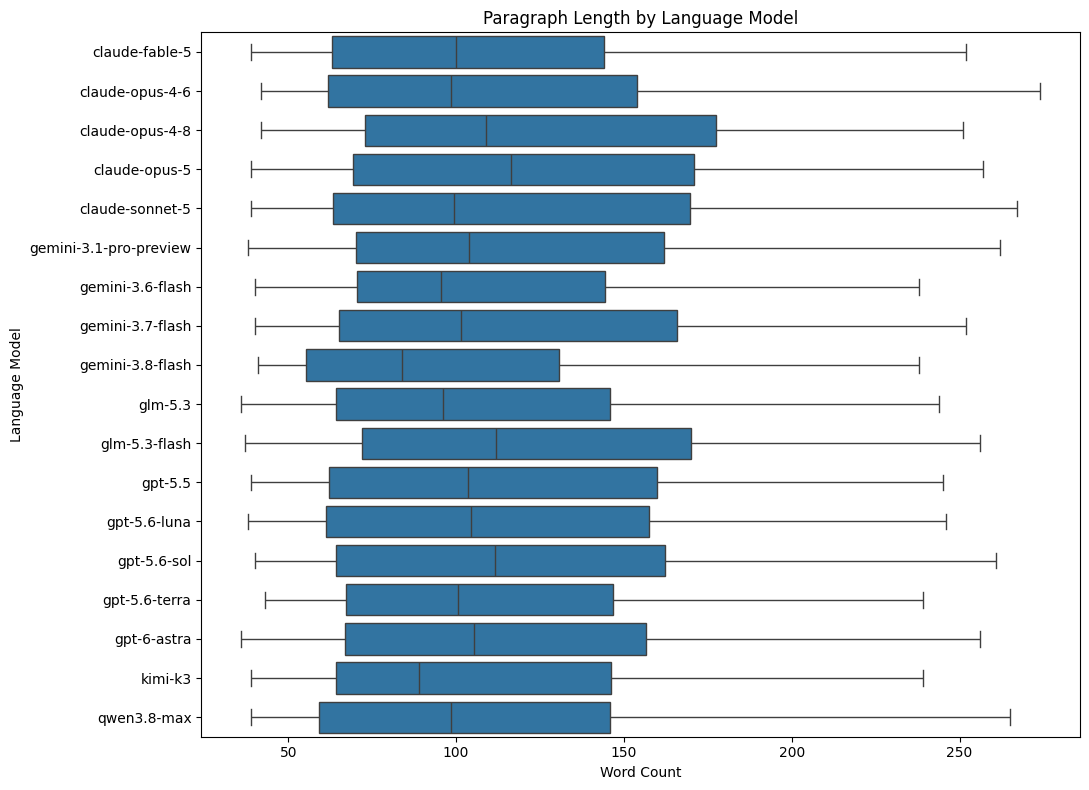

In [ ]:

exploration = data.copy()
exploration["word_count"] = (exploration["text"].str.split().str.len())

display(exploration.groupby("model")["word_count"].agg(["min", "median", "mean", "max"]).round(1))

plt.figure(figsize=(11, 8))

sns.boxplot(data=exploration,x="word_count",y="model",order=sorted(exploration["model"].unique()))
plt.title("Paragraph Length by Language Model")
plt.xlabel("Word Count")
plt.ylabel("Language Model")
plt.tight_layout()
plt.show()

### Observations:

